# Single Turn and History Aware Baseline Models 
this notebook creates conversation level data partitions and evaluates two baseline phishing detection models. These models are a single trun model using only the xurrent message and a hsotry aware model using the current and preceing conversati0on turns. Both conditions use identical conversation level partitions to prevent data leakage. 

In [8]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [10]:
from pathlib import Path

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
)

In [11]:
current_folder = Path.cwd()

if current_folder.name == "notebooks":
    project_root = current_folder.parent
else:
    project_root = current_folder

data_path = (
    project_root
    / "data"
    / "processed"
    / "turn_level_cialdini_features.csv"
)

print("Project root:", project_root)
print("Data path:", data_path)
print("File exists:", data_path.exists())

Project root: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE
Data path: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\data\processed\turn_level_cialdini_features.csv
File exists: True


In [12]:
model_df = pd.read_csv(data_path)

print("Rows:", len(model_df))
print("Conversations:", model_df["conversation_id"].nunique())
print("Columns:", len(model_df.columns))

model_df.head()

Rows: 14850
Conversations: 1350
Columns: 35


,conversation_id,turn_number,speaker,message,scenario_class,information_class,label,source_split,source_row,turn_text,...,scarcity_cumulative_count,scarcity_cumulative_present,reciprocity_cumulative_count,reciprocity_cumulative_present,commitment_consistency_cumulative_count,commitment_consistency_cumulative_present,liking_cumulative_count,liking_cumulative_present,social_proof_cumulative_count,social_proof_cumulative_present
0,test_0000,1,Eric,"Hello Frank, I hope this message finds you wel...",AF,Patents and Trademarks,1.0,authors_test,0,"Eric: Hello Frank, I hope this message finds y...",...,0,0,0,0,0,0,1,1,0,0
1,test_0000,2,Frank,"Hello Eric, I'm thrilled to receive your messa...",AF,Patents and Trademarks,1.0,authors_test,0,"Frank: Hello Eric, I'm thrilled to receive you...",...,0,0,0,0,0,0,1,1,0,0
2,test_0000,3,Eric,"Hello Frank, I am truly impressed by your work...",AF,Patents and Trademarks,1.0,authors_test,0,"Eric: Hello Frank, I am truly impressed by you...",...,0,0,1,1,2,1,2,1,0,0
3,test_0000,4,Frank,"Hello Eric, thank you for your positive respon...",AF,Patents and Trademarks,1.0,authors_test,0,"Frank: Hello Eric, thank you for your positive...",...,0,0,1,1,2,1,3,1,0,0
4,test_0000,5,Eric,"Hello Frank, thank you for sharing the informa...",AF,Patents and Trademarks,1.0,authors_test,0,"Eric: Hello Frank, thank you for sharing the i...",...,0,0,1,1,3,1,3,1,0,0


## Validate Modeling Fields 

before creating model partitions, the required text, label and conversation fields are checked for missinf values and inconsistent labels. 


In [15]:
required_columns = [
    "conversation_id",
    "turn_id",
    "turn_text",
    "cumulative_history",
    "label",
    "source_split",
]

missing_columns = [
    column for column in required_columns 
    if column not in model_df.columns
]

print("Missing columns:", missing_columns)

if not missing_columns:
    print("\nMissing Values:")
    print(model_df[required_columns].isna().sum())

    labels_per_conversation = (
        model_df.groupby("conversation_id")["label"].nunique()
    )

    print(
        "\nConversations with inconsitent labels:",
        (labels_per_conversation > 1).sum()
    )

Missing columns: ['turn_id']


In [17]:
conversation_df = (
    model_df.groupby("conversation_id", as_index=False)
    .agg(
        label=("label", "first"),
        source_split=("source_split", "first"),
        number_of_turns=("turn_number", "count"),
    )
)

print("Conversation-level rows:", len(conversation_df))
print("\nConversation counts by source and label:")

display(
    pd.crosstab(
        conversation_df["source_split"],
        conversation_df["label"],
        margins=True,
    )
)

Conversation-level rows: 1350

Conversation counts by source and label:


label,0.0,1.0,All
source_split,,,
authors_test,300,600,900
authors_train,150,300,450
All,450,900,1350


## Create Conversation Level Partitions 

the original se-vsim test split is retained as the held out test set. the original training conversaions are divided into training and validtions partitions. splitting is perfromed by conversation ID so that turns from one conversation cannot appear in multiple partitions. 

In [19]:
author_train_df = conversation_df[
    conversation_df["source_split"] == "authors_train"
].copy()

author_test_df = conversation_df[
    conversation_df["source_split"] == "authors_test"
].copy()

train_conversations, validation_conversations = train_test_split(
    
    author_train_df,
    test_size=0.2,
    random_state=42,
    stratify=author_train_df["label"]

)

test_conversations = author_test_df.copy()

print("Training conversations:", len(train_conversations))
print("Validation conversations:", len(validation_conversations))
print("Test conversations:", len(test_conversations))


Training conversations: 360
Validation conversations: 90
Test conversations: 900


In [22]:
model_df["partition"] = pd.NA

model_df.loc[
    model_df["conversation_id"].isin(
        train_conversations["conversation_id"]
    ),
    "partition"
] = "train"

model_df.loc[
    model_df["conversation_id"].isin(
        validation_conversations["conversation_id"]
    ),
    "partition"
] = "validation"

model_df.loc[
    model_df["conversation_id"].isin(
        test_conversations["conversation_id"]
    ),
    "partition"
] = "test"

print("Turns by partition:")
print(model_df["partition"].value_counts(dropna=False))

print(
    "\nTurns without a partition:",
    model_df["partition"].isna().sum()
)

Turns by partition:
partition
test          9900
train         3960
validation     990
Name: count, dtype: int64

Turns without a partition: 0


## Validate and Save Partitions

Conversation IDs are checked for overlap before modeling. The final partition assignments are saved so every model condition uses the same training, validation, and testing conversations.

In [23]:
train_ids = set(train_conversations["conversation_id"])
validation_ids = set(validation_conversations["conversation_id"])
test_ids = set(test_conversations["conversation_id"])

print(
    "Train-validation overlap:",
    len(train_ids.intersection(validation_ids))
)

print(
    "Train-test overlap:",
    len(train_ids.intersection(test_ids))
)

print(
    "Validation-test overlap:",
    len(validation_ids.intersection(test_ids))
)

print(
    "Total unique partitioned conversations:",
    len(train_ids | validation_ids | test_ids)
)

Train-validation overlap: 0
Train-test overlap: 0
Validation-test overlap: 0
Total unique partitioned conversations: 1350


In [24]:
partition_summary = pd.crosstab(
    model_df["partition"],
    model_df["label"],
    margins=True,
)

partition_summary

label,0.0,1.0,All
partition,,,
test,3300,6600,9900
train,1320,2640,3960
validation,330,660,990
All,4950,9900,14850


In [25]:
partition_df = (
    model_df[
        ["conversation_id", "label", "source_split", "partition"]
    ]
    .drop_duplicates(subset="conversation_id")
    .sort_values("conversation_id")
    .reset_index(drop=True)
)

partition_path = (
    project_root
    / "data"
    / "processed"
    / "conversation_partitions.csv"
)

partition_df.to_csv(partition_path, index=False)

print("Saved to:", partition_path)
print("Saved conversations:", len(partition_df))

Saved to: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\data\processed\conversation_partitions.csv
Saved conversations: 1350


## Single-Turn Text Baseline

The single-turn baseline uses only `turn_text`. It does not receive earlier messages, Cialdini features, or privileged SE-VSim metadata.

In [29]:
train_turns = model_df[
    model_df["partition"] == "train"
].copy()

validation_turns = model_df[
    model_df["partition"] == "validation"
].copy()

X_train_single = train_turns["turn_text"].fillna("")
y_train = train_turns["label"].astype(int)

X_validation_single = (
    validation_turns["turn_text"].fillna("")
)

y_validation = validation_turns["label"].astype(int)

print("Training examples:", len(X_train_single))
print("Validation examples:", len(X_validation_single))
print("Training labels:")
print(y_train.value_counts().sort_index())

Training examples: 3960
Validation examples: 990
Training labels:
label
0    1320
1    2640
Name: count, dtype: int64


In [30]:
single_turn_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True,
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
        ),
    ),
])

single_turn_model.fit(
    X_train_single,
    y_train,
)

print("Single-turn model training complete.")

Single-turn model training complete.


### Single Turn Validation Results

The model is evaluated on covnersations excluded from training. Performance includes accuracy, precision, recall, F1 score, false-positive rate, false-negatice rate, and a confusion matrix.



In [32]:
def evaluate_predictions(y_true, y_pred, model_name):
    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0,1]).ravel()
    false_positive_rate = fp / (fp + tn)
    false_negative_rate = fn / (fn + tp)

    results = {
        "Model": model_name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1 Score": f1,
        "False Positive Rate": false_positive_rate,
        "False Negative Rate": false_negative_rate,
        "true_negatives": tn,
        "false_positives": fp,
        "false_negatives": fn,
        "true_positives": tp,
    }

    return results

In [33]:
single_validation_predictions = (
    single_turn_model.predict(X_validation_single)
)

single_validation_results = evaluate_predictions(
    y_validation,
    single_validation_predictions,
    "Single-turn Baseline",
)

display(
    pd.DataFrame([single_validation_results]).round(4)
)

print("\nClassification Report:")
print(
    classification_report(
        y_validation,
        single_validation_predictions,
        zero_division=0,
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_validation,
        single_validation_predictions,
        labels=[0, 1],
    )
)

,Model,Accuracy,Precision,Recall,F1 Score,False Positive Rate,False Negative Rate,true_negatives,false_positives,false_negatives,true_positives
0,Single-turn Baseline,0.7636,0.8227,0.8227,0.8227,0.3545,0.1773,213,117,117,543



Classification Report:
              precision    recall  f1-score   support

           0       0.65      0.65      0.65       330
           1       0.82      0.82      0.82       660

    accuracy                           0.76       990
   macro avg       0.73      0.73      0.73       990
weighted avg       0.76      0.76      0.76       990


Confusion Matrix:
[[213 117]
 [117 543]]


## History-Aware Text Baseline

The history-aware baseline uses `cumulative_history`, which contains the current message and all preceding turns in the same conversation. It uses the same partitions and model settings as the single-turn baseline so that the effect of conversational history can be compared directly.

In [34]:
X_train_history = (
    train_turns["cumulative_history"].fillna("")
)

X_validation_history = (
    validation_turns["cumulative_history"].fillna("")
)

print("Training examples (history):", len(X_train_history))
print("Validation examples (history):", len(X_validation_history))


Training examples (history): 3960
Validation examples (history): 990


In [35]:
history_model = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            lowercase=True,
            ngram_range=(1, 2),
            min_df=2,
            max_df=0.95,
            sublinear_tf=True,
        ),
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            class_weight="balanced",
            random_state=42,
        ),
    ),
])

history_model.fit(
    X_train_history,
    y_train,
)

print("History-aware model training complete.")

History-aware model training complete.


In [36]:
history_validation_predictions = (
    history_model.predict(X_validation_history)
)

history_validation_results = evaluate_predictions(
    y_validation,
    history_validation_predictions,
    "History-aware baseline",
)

display(
    pd.DataFrame([history_validation_results]).round(4)
)

print("\nClassification report:")
print(
    classification_report(
        y_validation,
        history_validation_predictions,
        target_names=["Benign", "Malicious"],
        zero_division=0,
    )
)

print("Confusion matrix:")
print(
    confusion_matrix(
        y_validation,
        history_validation_predictions,
        labels=[0, 1],
    )
)


,Model,Accuracy,Precision,Recall,F1 Score,False Positive Rate,False Negative Rate,true_negatives,false_positives,false_negatives,true_positives
0,History-aware baseline,0.8374,0.8519,0.9152,0.8824,0.3182,0.0848,225,105,56,604



Classification report:
              precision    recall  f1-score   support

      Benign       0.80      0.68      0.74       330
   Malicious       0.85      0.92      0.88       660

    accuracy                           0.84       990
   macro avg       0.83      0.80      0.81       990
weighted avg       0.83      0.84      0.83       990

Confusion matrix:
[[225 105]
 [ 56 604]]


In [38]:
validation_comparison = pd.DataFrame([
    single_validation_results,
    history_validation_results,
])

metric_columns = [
    "model",
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "false_positive_rate",
    "false_negative_rate",
]

validation_comparison = validation_comparison.rename(
    columns={
        "Model": "model",
        "Accuracy": "accuracy",
        "Precision": "precision",
        "Recall": "recall",
        "F1 Score": "f1_score",
        "False Positive Rate": "false_positive_rate",
        "False Negative Rate": "false_negative_rate",
    }
)

validation_comparison = validation_comparison[metric_columns]

validation_comparison.round(4)

,model,accuracy,precision,recall,f1_score,false_positive_rate,false_negative_rate
0,Single-turn Baseline,0.7636,0.8227,0.8227,0.8227,0.3545,0.1773
1,History-aware baseline,0.8374,0.8519,0.9152,0.8824,0.3182,0.0848


In [39]:
results_folder = project_root / "results"
results_folder.mkdir(parents=True, exist_ok=True)

validation_results_path = (
    results_folder
    / "baseline_validation_results.csv"
)

validation_comparison.to_csv(
    validation_results_path,
    index=False,
)

print("Saved to:", validation_results_path)

Saved to: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\results\baseline_validation_results.csv


## Validation Performance by Turn Number

Performance is measured separately for each conversation turn. This analysis examines whether the history-aware model benefits from accumulating additional conversational context.

In [41]:
validation_analysis = validation_turns[
    [
        "conversation_id",
        "turn_number",
        "label",
    ]
].copy()

validation_analysis["single_turn_prediction"] = (
    single_validation_predictions
)

validation_analysis["history_prediction"] = (
    history_validation_predictions
)

validation_analysis.head()

,conversation_id,turn_number,label,single_turn_prediction,history_prediction
9911,train_0001,1,0.0,1,1
9912,train_0001,2,0.0,1,1
9913,train_0001,3,0.0,1,1
9914,train_0001,4,0.0,1,1
9915,train_0001,5,0.0,1,1


In [43]:
turn_results = []

for turn_number in sorted(
    validation_analysis["turn_number"].unique()
):
    turn_data = validation_analysis[
        validation_analysis["turn_number"] == turn_number
    ]

    y_true_turn = turn_data["label"].astype(int)

    for model_name, prediction_column in [
        ("Single-turn baseline", "single_turn_prediction"),
        ("History-aware baseline", "history_prediction"),
    ]:
        turn_metrics = evaluate_predictions(
            y_true_turn,
            turn_data[prediction_column],
            model_name,
        )

        turn_metrics["turn_number"] = turn_number
        turn_results.append(turn_metrics)

turn_results_df = pd.DataFrame(turn_results)

turn_results_df = turn_results_df.rename(
    columns={
        "Model": "model",
        "Accuracy": "accuracy",
        "Precision": "precision",
        "Recall": "recall",
        "F1 Score": "f1_score",
        "False Positive Rate": "false_positive_rate",
        "False Negative Rate": "false_negative_rate",
    }
)

turn_metric_columns = [
    "turn_number",
    "model",
    "accuracy",
    "precision",
    "recall",
    "f1_score",
    "false_positive_rate",
    "false_negative_rate",
]

turn_results_df = turn_results_df[
    turn_metric_columns
]

turn_results_df.round(4)


,turn_number,model,accuracy,precision,recall,f1_score,false_positive_rate,false_negative_rate
0,1,Single-turn baseline,0.6222,0.7241,0.7000,0.7119,0.5333,0.3000
1,1,History-aware baseline,0.6444,0.7188,0.7667,0.7419,0.6000,0.2333
2,2,Single-turn baseline,0.5778,0.7115,0.6167,0.6607,0.5000,0.3833
3,2,History-aware baseline,0.6444,0.8043,0.6167,0.6981,0.3000,0.3833
4,3,Single-turn baseline,0.8778,0.8551,0.9833,0.9147,0.3333,0.0167
5,3,History-aware baseline,0.8444,0.8382,0.9500,0.8906,0.3667,0.0500
6,4,Single-turn baseline,0.8000,0.8000,0.9333,0.8615,0.4667,0.0667
7,4,History-aware baseline,0.8889,0.8788,0.9667,0.9206,0.2667,0.0333
8,5,Single-turn baseline,0.8444,0.8485,0.9333,0.8889,0.3333,0.0667
9,5,History-aware baseline,0.8667,0.8529,0.9667,0.9062,0.3333,0.0333


In [44]:
turn_results_path = (
    results_folder
    / "baseline_validation_results_by_turn.csv"
)

turn_results_df.to_csv(
    turn_results_path,
    index=False,
)

print("Saved to:", turn_results_path)
print("Saved rows:", len(turn_results_df))

Saved to: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\results\baseline_validation_results_by_turn.csv
Saved rows: 22


In [45]:
import matplotlib.pyplot as plt


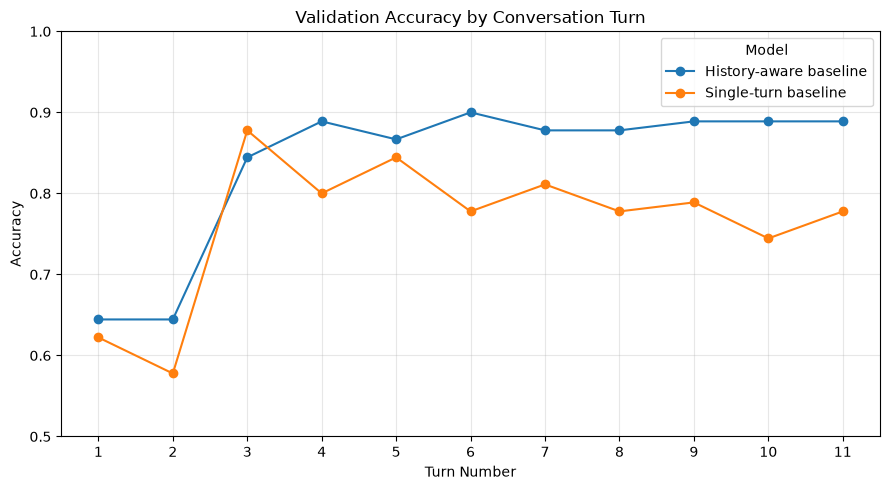

In [46]:
accuracy_by_turn = turn_results_df.pivot(
    index="turn_number",
    columns="model",
    values="accuracy",
)

accuracy_by_turn.plot(
    marker="o",
    figsize=(9, 5),
)

plt.title("Validation Accuracy by Conversation Turn")
plt.xlabel("Turn Number")
plt.ylabel("Accuracy")
plt.ylim(0.5, 1.0)
plt.xticks(range(1, 12))
plt.grid(alpha=0.3)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## Final Held Out Test Evaluation 

After fixing the model settings using validation results, each baseline is retrained using the combined training validation partitions. Final evaluation is then perfomred once on the original SE-VSim test split 


In [47]:
development_turns = model_df[
    model_df["partition"].isin(["train", "validation"])
].copy()

test_turns = model_df[
    model_df["partition"] == "test"
].copy()

y_development = development_turns["label"].astype(int)
y_test = test_turns["label"].astype(int)

print("Development examples:", len(development_turns))
print("Test examples:", len(test_turns))
print("\nTest labels:")
print(y_test.value_counts().sort_index())

Development examples: 4950
Test examples: 9900

Test labels:
label
0    3300
1    6600
Name: count, dtype: int64


In [48]:
from sklearn.base import clone

final_single_turn_model = clone(single_turn_model)
final_history_model = clone(history_model)

final_single_turn_model.fit(
    development_turns["turn_text"].fillna(""),
    y_development,
)

final_history_model.fit(
    development_turns["cumulative_history"].fillna(""),
    y_development,
)

print("Final baseline models trained.")

Final baseline models trained.


In [50]:
single_test_predictions = final_single_turn_model.predict(
    test_turns["turn_text"].fillna("")
)

history_test_predictions = final_history_model.predict(
    test_turns["cumulative_history"].fillna("")
)

single_test_results = evaluate_predictions(
    y_test,
    single_test_predictions,
    "Single-turn baseline",
)

history_test_results = evaluate_predictions(
    y_test,
    history_test_predictions,
    "History-aware baseline",
)

test_comparison = pd.DataFrame([
    single_test_results,
    history_test_results,
])

test_comparison = test_comparison.rename(
    columns={
        "Model": "model",
        "Accuracy": "accuracy",
        "Precision": "precision",
        "Recall": "recall",
        "F1 Score": "f1_score",
        "False Positive Rate": "false_positive_rate",
        "False Negative Rate": "false_negative_rate",
    }
)

display(
    test_comparison[
        [
            "model",
            "accuracy",
            "precision",
            "recall",
            "f1_score",
            "false_positive_rate",
            "false_negative_rate",
            "true_negatives",
            "false_positives",
            "false_negatives",
            "true_positives",
        ]
    ].round(4)
)

,model,accuracy,precision,recall,f1_score,false_positive_rate,false_negative_rate,true_negatives,false_positives,false_negatives,true_positives
0,Single-turn baseline,0.7796,0.8358,0.8330,0.8344,0.3273,0.1670,2220,1080,1102,5498
1,History-aware baseline,0.8460,0.8543,0.9271,0.8892,0.3164,0.0729,2256,1044,481,6119


In [51]:
test_results_path = (
    results_folder
    / "baseline_test_results.csv"
)

test_comparison.to_csv(
    test_results_path,
    index=False,
)

print("Saved to:", test_results_path)

Saved to: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\results\baseline_test_results.csv


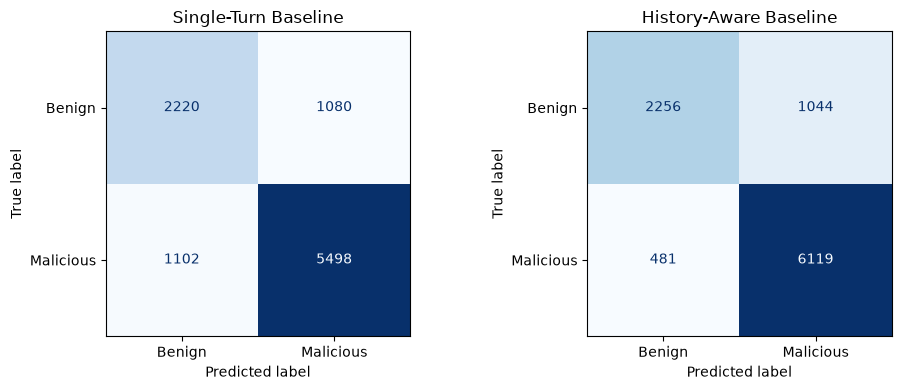

Saved to: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\results\baseline_confusion_matrices.png


In [52]:
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    single_test_predictions,
    display_labels=["Benign", "Malicious"],
    cmap="Blues",
    colorbar=False,
    ax=axes[0],
)

axes[0].set_title("Single-Turn Baseline")

ConfusionMatrixDisplay.from_predictions(
    y_test,
    history_test_predictions,
    display_labels=["Benign", "Malicious"],
    cmap="Blues",
    colorbar=False,
    ax=axes[1],
)

axes[1].set_title("History-Aware Baseline")

plt.tight_layout()

confusion_figure_path = (
    results_folder
    / "baseline_confusion_matrices.png"
)

plt.savefig(
    confusion_figure_path,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print("Saved to:", confusion_figure_path)

## Save Baseline Predictions

Held-out predictions and probabilities are saved with their conversation and turn identifiers. These records will support later error analysis and comparison with the Cialdini-enhanced model.

In [53]:
test_prediction_df = test_turns[
    [
        "conversation_id",
        "turn_number",
        "scenario_class",
        "label",
    ]
].copy()

test_prediction_df["single_turn_prediction"] = (
    single_test_predictions
)

test_prediction_df["single_turn_probability"] = (
    final_single_turn_model.predict_proba(
        test_turns["turn_text"].fillna("")
    )[:, 1]
)

test_prediction_df["history_prediction"] = (
    history_test_predictions
)

test_prediction_df["history_probability"] = (
    final_history_model.predict_proba(
        test_turns["cumulative_history"].fillna("")
    )[:, 1]
)

prediction_path = (
    results_folder
    / "baseline_test_predictions.csv"
)

test_prediction_df.to_csv(
    prediction_path,
    index=False,
)

print("Saved to:", prediction_path)
print("Saved prediction rows:", len(test_prediction_df))
print("Missing values:", test_prediction_df.isna().sum().sum())

test_prediction_df.head()

Saved to: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\results\baseline_test_predictions.csv
Saved prediction rows: 9900
Missing values: 0


,conversation_id,turn_number,scenario_class,label,single_turn_prediction,single_turn_probability,history_prediction,history_probability
0,test_0000,1,AF,1.0,1,0.708058,1,0.614454
1,test_0000,2,AF,1.0,0,0.498312,1,0.601749
2,test_0000,3,AF,1.0,1,0.881902,1,0.751356
3,test_0000,4,AF,1.0,1,0.873520,1,0.819158
4,test_0000,5,AF,1.0,1,0.969967,1,0.910772


## Final Baseline Validation

The completed baseline pipeline is checked for partition isolation, prediction completeness, valid prediction values, and consistent test-set size.

In [54]:
final_checks = {
    "partition_overlap": (
        len(train_ids & validation_ids)
        + len(train_ids & test_ids)
        + len(validation_ids & test_ids)
    ),
    "unassigned_turns": model_df["partition"].isna().sum(),
    "test_prediction_rows": len(test_prediction_df),
    "missing_prediction_values": (
        test_prediction_df.isna().sum().sum()
    ),
    "invalid_single_predictions": (
        ~test_prediction_df[
            "single_turn_prediction"
        ].isin([0, 1])
    ).sum(),
    "invalid_history_predictions": (
        ~test_prediction_df[
            "history_prediction"
        ].isin([0, 1])
    ).sum(),
}

final_checks_df = pd.DataFrame(
    final_checks.items(),
    columns=["check", "value"],
)

final_checks_df

,check,value
0,partition_overlap,0
1,unassigned_turns,0
2,test_prediction_rows,9900
3,missing_prediction_values,0
4,invalid_single_predictions,0
5,invalid_history_predictions,0


In [55]:
validation_path = (
    results_folder
    / "baseline_validation_checks.csv"
)

final_checks_df.to_csv(
    validation_path,
    index=False,
)

print("Saved to:", validation_path)

Saved to: c:\Users\josie\OneDrive\Desktop\School\Capstone\Phishing Detection\MTPD CAPSTONE\results\baseline_validation_checks.csv
